# 05. Машинне навчання: Прогнозування стартів у [T, T+1h) та Ablation Study (A, B, C, та post-hoc C')

Цей блокнот підсумовує результати Етапу 2 на Feature Store (`797,428` спокійних людино-годин, `is_active_T == 0`, `0` дублікатів):
- **Набір A (10 ознак):** часові цикли, `burden_last_6h`, `burden_last_24h` та Train-only кластери (`low_activity`, `medium_activity`, `high_activity`).
- **Набір B (13 ознак):** A + миттєвий стан сусідів о $T$ (`neighbors_active_count`, `neighbor_any_active`, `neighbor_active_ratio`).
- **Набір C (22 ознаки, головна передреєстрована конфігурація):** B + адаптивні частоти (`adaptive_rate_7d/14d/30d`), `national_active_count`, `onsets_last_24h` (Варіант А), `hours_since_last_alert` та лаги сусідів за 1, 2, 3 год (`neighbors_active_lag_1h/2h/3h`).
- **Набір C' (19 ознак, пост-хок експеримент):** B + `adaptive_rate_7d/14d/30d` + `neighbors_active_lag_1h/2h/3h` (без `national_active_count`, `hours_since_last_alert` та `onsets_last_24h`).
- **Пост-хок позначка:** головне порівняння було заздалегідь визначене як `Set C` проти адаптивного бейзлайну (`Adaptive 14-day Rolling`); вибір `Set B` за PR-AUC та конструювання `Set C'` зроблено після перегляду результатів на Test і є **пост-хок (post-hoc)**.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

reports_dir = Path("../reports/official")
val_df = pd.read_csv(reports_dir / "ml_validation_benchmark.csv")
test_df = pd.read_csv(reports_dir / "ml_models_benchmark.csv")
pre_df = pd.read_csv(reports_dir / "ml_test_pre_aug2025_benchmark.csv")
post_df = pd.read_csv(reports_dir / "ml_test_post_aug2025_benchmark.csv")
rec_df = pd.read_csv(reports_dir / "ml_recent_60d_benchmark.csv")
shift_df = pd.read_csv(reports_dir / "feature_shift_summary.csv")
shift_sub_df = pd.read_csv(reports_dir / "feature_shift_test_subperiods.csv")
imp_df = pd.read_csv(reports_dir / "feature_importance_lightgbm.csv")
details = json.loads((reports_dir / "test_evaluation_details.json").read_text(encoding="utf-8"))

## 1. Результати на Validation (2024-05 — 2025-05, підбір порогів $p^*$)

In [2]:
display(val_df)

,model,feature_set,threshold,precision,recall,f2_score,pr_auc,brier_score
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.230757,0.075949,0.087718,NaN,0.119719
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.194216,0.749250,0.476754,0.194529,0.086577
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.200804,0.761400,0.488594,0.250806,0.083686
3,LogReg (Set A: No Spatial),"A (Time, Burden & Cluster)",0.517586,0.190696,0.778461,0.481590,0.266656,0.235025
4,LogReg (Set B: With Spatial),B (A + Spatial at T),0.561207,0.212022,0.771223,0.504894,0.288191,0.245719
5,LogReg (Set C: Spatial + Adaptive),"C (B + Adaptive, Nat & Lags)",0.565172,0.212014,0.823131,0.522130,0.270086,0.252085
6,LogReg (Set C': Adaptive + Lags),C' (B + Adaptive & Lags only),0.541379,0.221005,0.776910,0.516882,0.288399,0.228395
7,LightGBM (Set A: No Spatial),"A (Time, Burden & Cluster)",0.093276,0.206074,0.740926,0.487744,0.268010,0.082417
8,LightGBM (Set B: With Spatial),B (A + Spatial at T),0.109138,0.215688,0.815583,0.524065,0.296142,0.079958
9,LightGBM (Set C: Spatial + Adaptive),"C (B + Adaptive, Nat & Lags)",0.128966,0.232055,0.788905,0.533069,0.301225,0.079568


## 2. Фінальний бенчмарк на повному Test (червень 2025 — вересень 2026, Day-Block Bootstrap N=500)

In [3]:
display(test_df)

,model,feature_set,frozen_threshold,precision,recall,f2_score,f2_ci_95,pr_auc,pr_auc_ci_95,brier_score,prec_at_adapt_recall,rec_at_adapt_prec,lift_f2_over_best_baseline_pct,lift_prauc_over_best_baseline_pct
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.290853,0.089037,0.103384,"[0.096, 0.111]",NaN,-,0.115905,NaN,NaN,-80.491508,NaN
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.227355,0.722519,0.503292,"[0.495, 0.511]",0.220406,"[0.212, 0.228]",0.086782,0.211073,0.697383,-5.029333,-27.289315
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.231394,0.782272,0.529945,"[0.520, 0.538]",0.303127,"[0.292, 0.315]",0.081774,0.231394,0.782272,0.000000,0.000000
3,LogReg (Set A: No Spatial),"A (Time, Burden & Cluster)",0.517586,0.235451,0.778815,0.532869,"[0.524, 0.541]",0.388101,"[0.377, 0.399]",0.200706,0.233878,0.787062,0.551793,28.032428
4,LogReg (Set B: With Spatial),B (A + Spatial at T),0.561207,0.240036,0.811951,0.549907,"[0.541, 0.558]",0.390327,"[0.380, 0.400]",0.233705,0.251428,0.832346,3.766875,28.766730
5,LogReg (Set C: Spatial + Adaptive),"C (B + Adaptive, Nat & Lags)",0.565172,0.211468,0.893284,0.543083,"[0.535, 0.550]",0.317262,"[0.306, 0.328]",0.287462,0.252660,0.844988,2.479141,4.663014
6,LogReg (Set C': Adaptive + Lags),C' (B + Adaptive & Lags only),0.541379,0.241225,0.816247,0.552732,"[0.544, 0.561]",0.338575,"[0.327, 0.350]",0.226524,0.255611,0.839605,4.299893,11.693852
7,LightGBM (Set A: No Spatial),"A (Time, Burden & Cluster)",0.093276,0.254333,0.745679,0.537860,"[0.529, 0.546]",0.348187,"[0.337, 0.359]",0.078449,0.235330,0.788938,1.493687,14.864820
8,LightGBM (Set B: With Spatial),B (A + Spatial at T),0.109138,0.235274,0.857827,0.560959,"[0.552, 0.570]",0.374132,"[0.363, 0.386]",0.076120,0.268055,0.866025,5.852415,23.424068
9,LightGBM (Set C: Spatial + Adaptive),"C (B + Adaptive, Nat & Lags)",0.128966,0.230016,0.858272,0.555059,"[0.547, 0.562]",0.332948,"[0.323, 0.343]",0.078281,0.262516,0.854321,4.739003,9.837668


## 3. Оцінка всередині Test до та після 2025-08-01 і на останніх 60 днях (09.07.2026 — 07.09.2026)

In [4]:
print("=== Test до 2025-08-01 (28,929 год, базова частка 9.62%) ===")
display(pre_df)
print("\n=== Test після 2025-08-01 (168,154 год, базова частка 10.39%) ===")
display(post_df)
print("\n=== Останні 60 днів (23,646 год, базова частка 12.65%) ===")
display(rec_df)

=== Test до 2025-08-01 (28,929 год, базова частка 9.62%) ===


,model,feature_set,frozen_threshold,precision,recall,f2_score,f2_ci_95,pr_auc,pr_auc_ci_95,brier_score,prec_at_adapt_recall,rec_at_adapt_prec,lift_f2_over_best_baseline_pct,lift_prauc_over_best_baseline_pct
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.202686,0.059669,0.069474,"[0.049, 0.090]",NaN,-,0.113001,NaN,NaN,-84.913180,NaN
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.182067,0.740115,0.458840,"[0.440, 0.477]",0.179357,"[0.162, 0.199]",0.082804,0.168709,0.202732,-0.358546,-34.423524
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.198978,0.685838,0.460491,"[0.444, 0.477]",0.273507,"[0.259, 0.288]",0.079424,0.174114,0.685838,0.000000,0.000000
3,LogReg (Set A: No Spatial),"A (Time, Burden & Cluster)",0.517586,0.180577,0.755931,0.461711,"[0.443, 0.479]",0.293398,"[0.275, 0.313]",0.232977,0.172891,0.687275,0.264791,7.272256
4,LogReg (Set B: With Spatial),B (A + Spatial at T),0.561207,0.199136,0.745507,0.481363,"[0.466, 0.498]",0.287652,"[0.272, 0.306]",0.248863,0.190614,0.747304,4.532435,5.171686
5,LogReg (Set C: Spatial + Adaptive),"C (B + Adaptive, Nat & Lags)",0.565172,0.205285,0.773544,0.497895,"[0.483, 0.513]",0.257926,"[0.243, 0.275]",0.240448,0.203326,0.796190,8.122455,-5.696805
6,LogReg (Set C': Adaptive + Lags),C' (B + Adaptive & Lags only),0.541379,0.215390,0.696262,0.481338,"[0.467, 0.495]",0.278286,"[0.264, 0.294]",0.216193,0.192311,0.752696,4.527017,1.747027
7,LightGBM (Set A: No Spatial),"A (Time, Burden & Cluster)",0.093276,0.198430,0.717829,0.471168,"[0.455, 0.488]",0.289185,"[0.270, 0.310]",0.077077,0.180896,0.717110,2.318606,5.732114
8,LightGBM (Set B: With Spatial),B (A + Spatial at T),0.109138,0.210091,0.784328,0.507112,"[0.492, 0.522]",0.310530,"[0.293, 0.328]",0.075570,0.210257,0.823868,10.124025,13.536278
9,LightGBM (Set C: Spatial + Adaptive),"C (B + Adaptive, Nat & Lags)",0.128966,0.232602,0.712437,0.504351,"[0.487, 0.522]",0.300575,"[0.284, 0.321]",0.075813,0.209796,0.816319,9.524604,9.896582



=== Test після 2025-08-01 (168,154 год, базова частка 10.39%) ===


,model,feature_set,frozen_threshold,precision,recall,f2_score,f2_ci_95,pr_auc,pr_auc_ci_95,brier_score,prec_at_adapt_recall,rec_at_adapt_prec,lift_f2_over_best_baseline_pct,lift_prauc_over_best_baseline_pct
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.304275,0.093714,0.108768,"[0.102, 0.116]",NaN,-,0.116405,NaN,NaN,-79.899528,NaN
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.237011,0.719716,0.511406,"[0.502, 0.521]",0.229450,"[0.221, 0.238]",0.087466,0.220104,0.723723,-5.491348,-25.211924
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.236674,0.797630,0.541121,"[0.531, 0.551]",0.306801,"[0.294, 0.320]",0.082179,0.239398,0.797630,0.000000,0.000000
3,LogReg (Set A: No Spatial),"A (Time, Burden & Cluster)",0.517586,0.247000,0.782459,0.545812,"[0.537, 0.555]",0.402470,"[0.392, 0.413]",0.195154,0.247089,0.803927,0.866861,31.182973
4,LogReg (Set B: With Spatial),B (A + Spatial at T),0.561207,0.247370,0.822533,0.561447,"[0.553, 0.570]",0.404043,"[0.395, 0.415]",0.231097,0.262309,0.845432,3.756347,31.695623
5,LogReg (Set C: Spatial + Adaptive),"C (B + Adaptive, Nat & Lags)",0.565172,0.212332,0.912354,0.549821,"[0.541, 0.559]",0.326593,"[0.314, 0.339]",0.295551,0.265685,0.859915,1.607763,6.451173
6,LogReg (Set C': Adaptive + Lags),C' (B + Adaptive & Lags only),0.541379,0.245128,0.835356,0.563833,"[0.554, 0.574]",0.346953,"[0.334, 0.359]",0.228301,0.267077,0.854019,4.197226,13.087352
7,LightGBM (Set A: No Spatial),"A (Time, Burden & Cluster)",0.093276,0.265743,0.750114,0.549719,"[0.541, 0.560]",0.357726,"[0.348, 0.368]",0.078685,0.247366,0.799347,1.588984,16.598790
8,LightGBM (Set B: With Spatial),B (A + Spatial at T),0.109138,0.239397,0.869533,0.569649,"[0.561, 0.579]",0.383674,"[0.373, 0.394]",0.076214,0.277665,0.874227,5.271970,25.056345
9,LightGBM (Set C: Spatial + Adaptive),"C (B + Adaptive, Nat & Lags)",0.128966,0.229687,0.881498,0.562336,"[0.553, 0.571]",0.338578,"[0.327, 0.350]",0.078705,0.271481,0.866384,3.920586,10.357694



=== Останні 60 днів (23,646 год, базова частка 12.65%) ===


,model,feature_set,frozen_threshold,precision,recall,f2_score,f2_ci_95,pr_auc,pr_auc_ci_95,brier_score,prec_at_adapt_recall,rec_at_adapt_prec,lift_f2_over_best_baseline_pct,lift_prauc_over_best_baseline_pct
0,Baseline 1: True Naive Persistence,NaN,0.500000,0.391667,0.141377,0.162094,"[0.145, 0.181]",NaN,-,0.136429,NaN,NaN,-74.791536,NaN
1,Baseline 2: Historical Lookup Table,NaN,0.085235,0.331462,0.730281,0.588631,"[0.564, 0.613]",0.325750,"[0.295, 0.357]",0.103754,0.317258,0.804144,-8.457358,-11.528568
2,Baseline 3: Adaptive 14-day Rolling,NaN,0.089195,0.298521,0.903743,0.643013,"[0.620, 0.664]",0.368198,"[0.333, 0.406]",0.091070,0.341159,0.903743,0.000000,0.000000
3,LogReg (Set A: No Spatial),"A (Time, Burden & Cluster)",0.517586,0.354982,0.827540,0.653540,"[0.636, 0.674]",0.505829,"[0.480, 0.531]",0.169332,0.384906,0.898061,1.637004,37.379610
4,LogReg (Set B: With Spatial),B (A + Spatial at T),0.561207,0.327045,0.863302,0.650106,"[0.626, 0.674]",0.478765,"[0.444, 0.510]",0.206368,0.376004,0.912433,1.102978,30.029449
5,LogReg (Set C: Spatial + Adaptive),"C (B + Adaptive, Nat & Lags)",0.565172,0.257808,0.954545,0.619630,"[0.592, 0.643]",0.388891,"[0.354, 0.423]",0.297450,0.356642,0.914439,-3.636488,5.620280
6,LogReg (Set C': Adaptive + Lags),C' (B + Adaptive & Lags only),0.541379,0.309049,0.896056,0.649373,"[0.622, 0.675]",0.380270,"[0.343, 0.417]",0.230422,0.365953,0.910428,0.988977,3.278815
7,LightGBM (Set A: No Spatial),"A (Time, Burden & Cluster)",0.093276,0.369757,0.813168,0.655866,"[0.639, 0.674]",0.450056,"[0.423, 0.477]",0.088450,0.384401,0.896056,1.998784,22.232253
8,LightGBM (Set B: With Spatial),B (A + Spatial at T),0.109138,0.299227,0.905080,0.644210,"[0.617, 0.670]",0.454075,"[0.424, 0.481]",0.085324,0.370646,0.905414,0.186048,23.323684
9,LightGBM (Set C: Spatial + Adaptive),"C (B + Adaptive, Nat & Lags)",0.128966,0.273260,0.935495,0.630093,"[0.603, 0.654]",0.380919,"[0.348, 0.416]",0.089485,0.344467,0.903409,-2.009323,3.455054


## 4. Аналіз зсуву розподілу ознак (Train / Val / Test) та парні різниці (Day-Block Bootstrap N=500)
Ймовірна причина погіршення `Set C` відносно `Set B` — сильний зсув розподілу ознак між Train і Test (частково реальний, частково, можливо, через зміну визначення та логування тривоги в серпні 2025 р.).

In [5]:
print("=== Середні значення ознак за Train / Val / Test ===")
display(shift_df)
print("\n=== Середні значення ознак усередині Test до і після 2025-08-01 ===")
display(shift_sub_df)
print("\n=== Парні різниці на повному Test (Day-Block Bootstrap N=500) ===")
display(pd.DataFrame(details["paired_day_bootstrap_500_test"]).T)
print("\n=== Парні різниці на Test до 2025-08-01 ===")
display(pd.DataFrame(details["paired_day_bootstrap_500_pre_aug2025"]).T)
print("\n=== Парні різниці на Test після 2025-08-01 ===")
display(pd.DataFrame(details["paired_day_bootstrap_500_post_aug2025"]).T)
print("\n=== Парні різниці на останніх 60 днях ===")
display(pd.DataFrame(details["paired_day_bootstrap_500_recent_60d"]).T)

=== Середні значення ознак за Train / Val / Test ===


,feature,train_mean,val_mean,test_mean,test_vs_train_ratio
0,national_active_count,1.172488,3.061495,5.544999,4.729258
1,neighbors_active_count,0.127934,0.318789,0.516909,4.040446
2,hours_since_last_alert,32.642113,30.133961,42.668823,1.307171
3,adaptive_rate_7d,0.074852,0.082116,0.077673,1.037693
4,adaptive_rate_14d,0.075068,0.082527,0.077748,1.035693
5,adaptive_rate_30d,0.075363,0.083195,0.076968,1.021292
6,onsets_last_24h,1.732717,1.892105,1.798486,1.037957
7,burden_last_6h,0.071613,0.107668,0.102071,1.425312
8,burden_last_24h,0.075791,0.124652,0.117271,1.547301
9,target_onset_next_1h,0.081044,0.101696,0.102749,1.267820



=== Середні значення ознак усередині Test до і після 2025-08-01 ===


,feature,test_pre_2025_08_01_mean,test_post_2025_08_01_mean,post_vs_pre_ratio
0,national_active_count,3.167237,5.954066,1.879893
1,neighbors_active_count,0.338173,0.547659,1.619464
2,hours_since_last_alert,22.779318,46.090591,2.023353
3,adaptive_rate_7d,0.073329,0.078421,1.069446
4,adaptive_rate_14d,0.073311,0.078511,1.070938
5,adaptive_rate_30d,0.070761,0.078035,1.102798
6,onsets_last_24h,1.747209,1.807308,1.034397
7,burden_last_6h,0.107798,0.101086,0.937731
8,burden_last_24h,0.127019,0.115594,0.910054
9,target_onset_next_1h,0.096166,0.103881,1.080220



=== Парні різниці на повному Test (Day-Block Bootstrap N=500) ===


...

,mean,ci_low,ci_high
PRIMARY_lgb_C_minus_adaptive_prauc,0.027407,0.011697,0.045542
PRIMARY_lgb_C_minus_adaptive_f2,0.044067,0.026981,0.062463
lgb_Cprime_minus_adaptive_prauc,0.038883,0.026521,0.050996
lgb_Cprime_minus_adaptive_f2,0.050157,0.032254,0.070016
lgb_Cprime_minus_B_prauc,0.001876,-0.007634,0.012790
lgb_Cprime_minus_B_f2,0.003484,-0.007791,0.013377
lgb_Cprime_minus_C_prauc,0.011476,-0.001235,0.023735
lgb_Cprime_minus_C_f2,0.006089,-0.001208,0.013491
lr_C_minus_adaptive_prauc,-0.015103,-0.028815,-0.000642
lr_C_minus_adaptive_f2,0.037379,0.024718,0.051220



=== Парні різниці на Test після 2025-08-01 ===


,mean,ci_low,ci_high
PRIMARY_lgb_C_minus_adaptive_prauc,0.031923,0.024044,0.040183
PRIMARY_lgb_C_minus_adaptive_f2,0.021229,0.015867,0.026925
lgb_Cprime_minus_adaptive_prauc,0.051394,0.044528,0.058703
lgb_Cprime_minus_adaptive_f2,0.035821,0.030932,0.040573
lgb_Cprime_minus_B_prauc,-0.025370,-0.034300,-0.017020
lgb_Cprime_minus_B_f2,0.007385,0.003894,0.010486
lgb_Cprime_minus_C_prauc,0.019471,0.013247,0.025483
lgb_Cprime_minus_C_f2,0.014592,0.011413,0.018033
lr_C_minus_adaptive_prauc,0.019823,0.014427,0.025957
lr_C_minus_adaptive_f2,0.008654,0.003322,0.013906



=== Парні різниці на останніх 60 днях ===


,mean,ci_low,ci_high
PRIMARY_lgb_C_minus_adaptive_prauc,0.012584,-0.005513,0.031381
PRIMARY_lgb_C_minus_adaptive_f2,-0.013339,-0.022287,-0.004776
lgb_Cprime_minus_adaptive_prauc,0.031444,0.011074,0.051074
lgb_Cprime_minus_adaptive_f2,0.009436,-0.000106,0.018934
lgb_Cprime_minus_B_prauc,-0.053344,-0.074263,-0.032687
lgb_Cprime_minus_B_f2,0.008587,0.001152,0.016128
lgb_Cprime_minus_C_prauc,0.018859,0.007622,0.029651
lgb_Cprime_minus_C_f2,0.022774,0.016191,0.029772
lr_C_minus_adaptive_prauc,0.020494,0.005156,0.034902
lr_C_minus_adaptive_f2,-0.024019,-0.032619,-0.016058


## 5. Важливість 22 ознак у LightGBM (Set C) та фінальні графіки

,feature,feature_ua,gain,split
0,adaptive_rate_14d,Адаптивна частота за 14 діб,158122.982360,204
1,adaptive_rate_30d,Адаптивна частота за 30 діб,70634.945930,271
2,adaptive_rate_7d,Адаптивна частота за 7 діб,41422.989015,202
3,national_active_count,Активних областей по країні о T,38893.656739,397
4,hour_cos,Година доби (косинус),27332.325878,393
5,hour_sin,Година доби (синус),27267.342253,412
6,hours_since_last_alert,Годин від кінця останньої тривоги,26743.350925,579
7,month,Місяць (сезонність),26006.035243,487
8,neighbors_active_count,Кількість активних сусідів о T,20703.494350,62
9,onsets_last_24h,Кількість стартів за 24 год,10398.017237,105


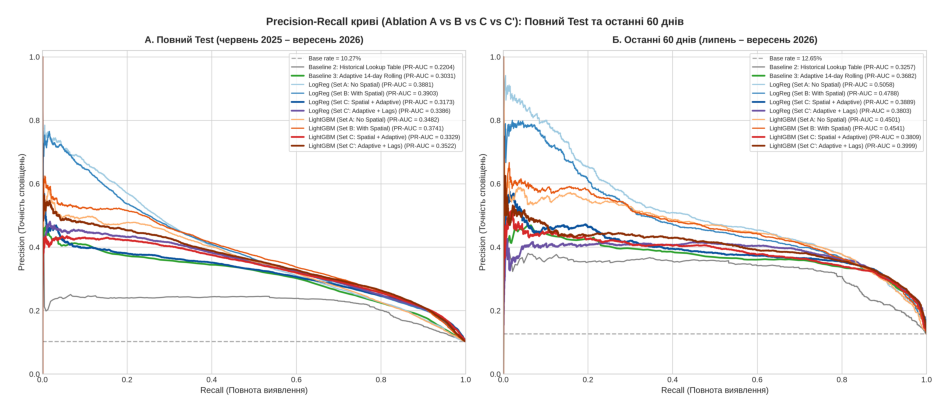

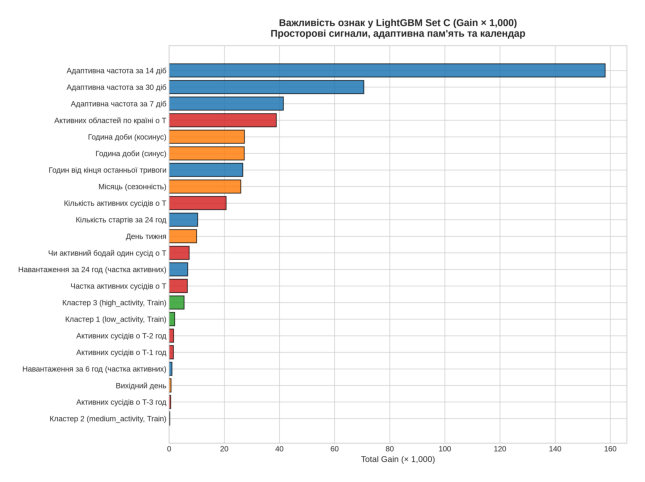

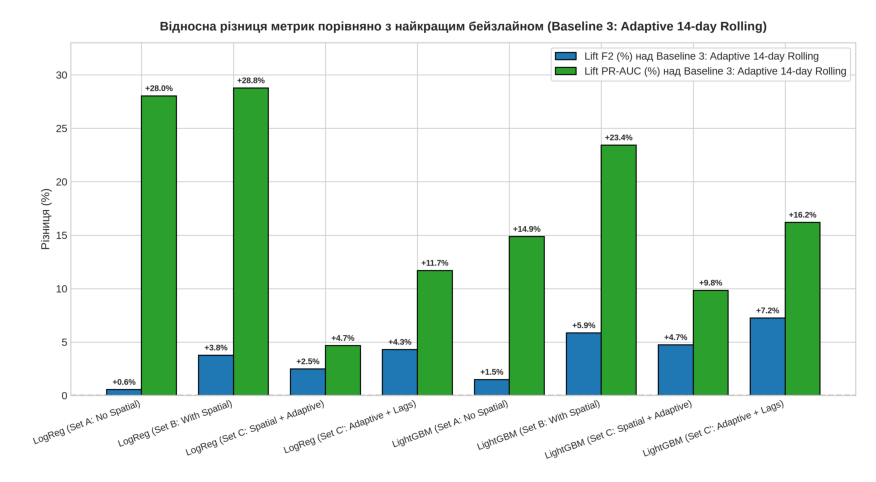

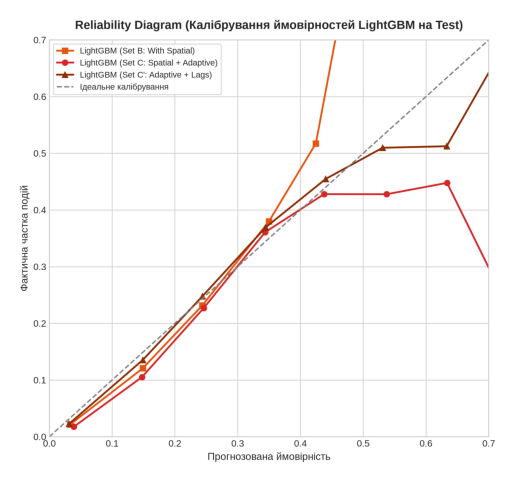

In [6]:
display(imp_df)
for fig_name in ["10_test_pr_curves_comparison.png", "11_feature_importance_lightgbm.png", "12_lift_over_baselines.png", "13_calibration_reliability_diagram.png"]:
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.imshow(mpimg.imread(reports_dir / "figures" / fig_name))
    ax.axis("off")
    plt.show()